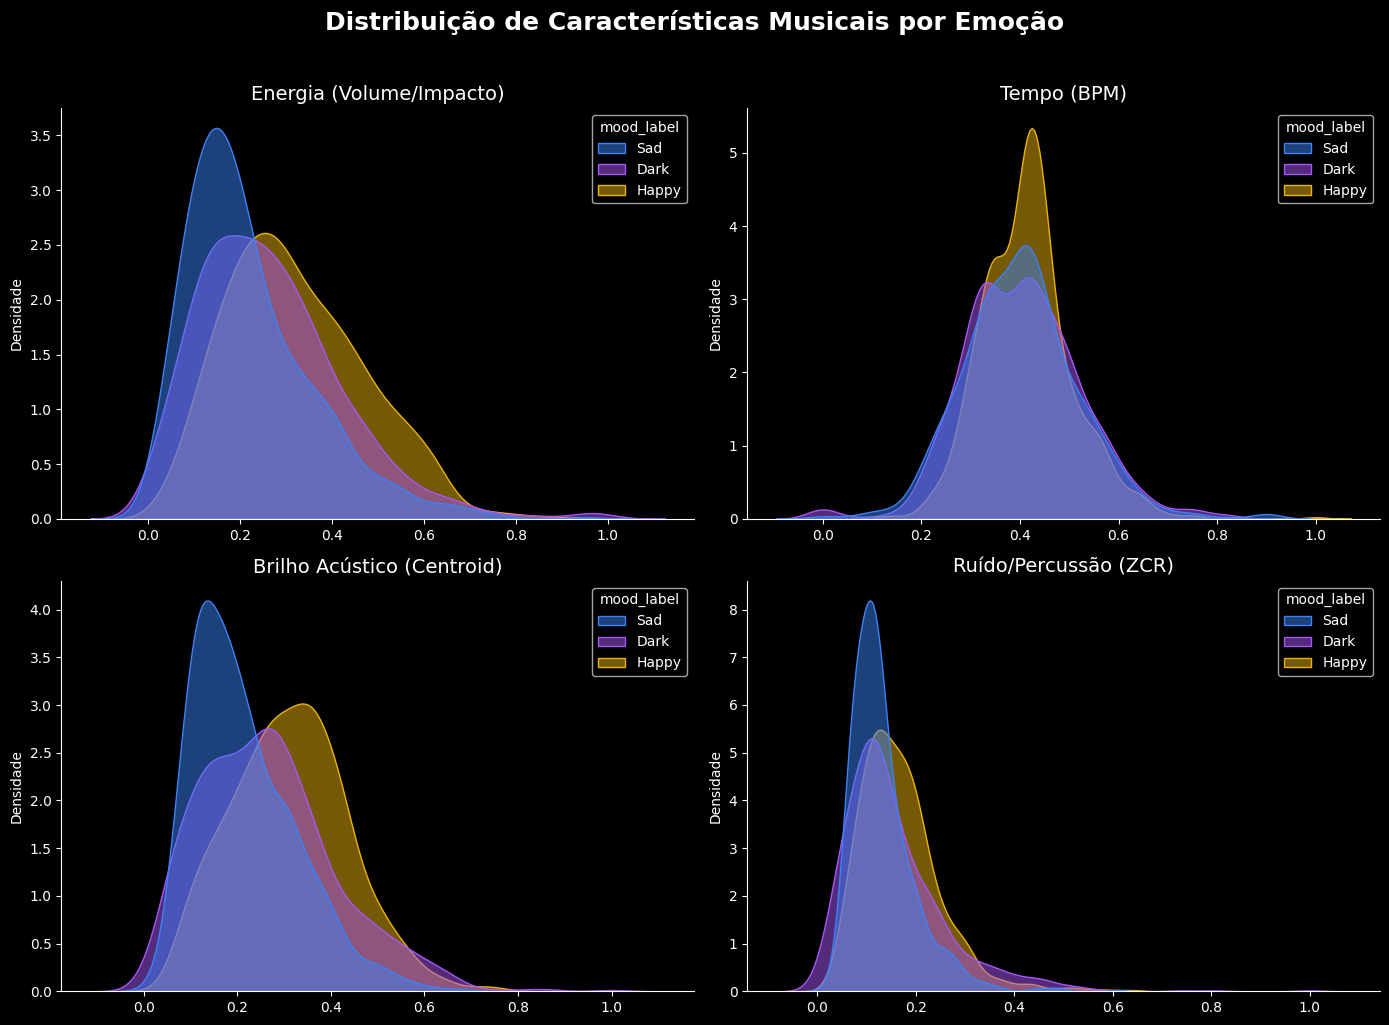

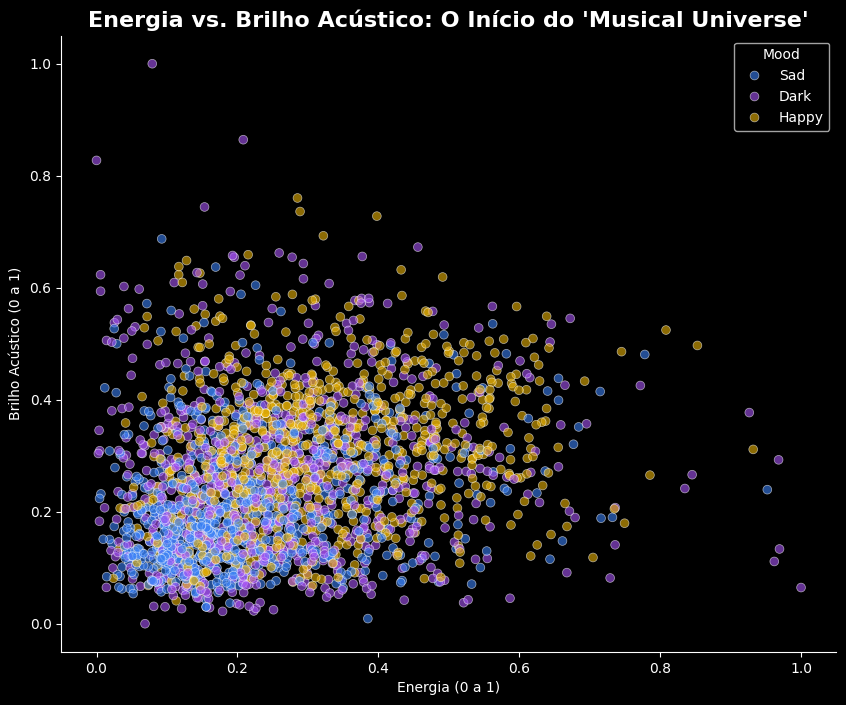

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuração Estética Editorial (Dark Mode, como planejado para o site)
plt.style.use('dark_background')
cores_mood = {"Sad": "#3b82f6", "Happy": "#eab308", "Dark": "#a855f7"} # Azul, Amarelo, Roxo

# 2. Carga dos Dados
df = pd.read_parquet("../data/processed/analytical_base_table.parquet")

# Criar coluna categórica de Mood para facilitar os gráficos
def assign_mood(row):
    if row['is_sad']: return 'Sad'
    if row['is_happy']: return 'Happy'
    if row['is_dark']: return 'Dark'
    return 'Unknown'

df['mood_label'] = df.apply(assign_mood, axis=1)

# 3. PERGUNTA 1: O que caracteriza o som de cada emoção? (Evidence)
features_plot = ['energy_rms_norm', 'tempo_bpm_norm', 'spectral_centroid_norm', 'zcr_norm']
nomes_amigaveis = ['Energia (Volume/Impacto)', 'Tempo (BPM)', 'Brilho Acústico (Centroid)', 'Ruído/Percussão (ZCR)']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Distribuição de Características Musicais por Emoção", fontsize=18, fontweight='bold', y=1.02)

for ax, feature, name in zip(axes.flatten(), features_plot, nomes_amigaveis):
    sns.kdeplot(data=df, x=feature, hue='mood_label', palette=cores_mood, fill=True, ax=ax, alpha=0.5, common_norm=False)
    ax.set_title(name, fontsize=14)
    ax.set_xlabel("")
    ax.set_ylabel("Densidade")
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# 4. PERGUNTA 2: A tristeza é apenas uma dimensão de baixa energia?
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=df, 
    x='energy_rms_norm', 
    y='spectral_centroid_norm', 
    hue='mood_label', 
    palette=cores_mood, 
    alpha=0.6, 
    s=40
)
plt.title("Energia vs. Brilho Acústico: O Início do 'Musical Universe'", fontsize=16, fontweight='bold')
plt.xlabel("Energia (0 a 1)")
plt.ylabel("Brilho Acústico (0 a 1)")
plt.legend(title="Mood")
sns.despine()
plt.show()

In [1]:
import sys
print(sys.executable)

/usr/bin/python3.11
